In [7]:
from pathlib import Path
import os
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Project root
PROJECT_ROOT = Path.cwd().parent

print("Project root:", PROJECT_ROOT)

Project root: d:\BioTranscribe-Transformer


In [8]:
from pathlib import Path

DATA_ROOT = PROJECT_ROOT / "data" / "pubmedqa"

print("Everything inside data/pubmedqa:\n")

for item in DATA_ROOT.rglob("*"):
    if item.is_dir():
        print("📁", item)
    else:
        print("📄", item)

Everything inside data/pubmedqa:

📄 d:\BioTranscribe-Transformer\data\pubmedqa\ori_pqal.json


## Load PubMedQA

In [9]:
# Path to PubMedQA dataset
DATA_FILE = PROJECT_ROOT / "data" / "pubmedqa" / "ori_pqal.json"

# Load JSON data
with open(DATA_FILE, "r", encoding="utf-8") as f:
    pubmedqa_data = json.load(f)

print("Dataset loaded successfully!")
print("Number of records:", len(pubmedqa_data))

Dataset loaded successfully!
Number of records: 1000


## Understanding the structure

In [10]:
# Inspect the first record
first_id = next(iter(pubmedqa_data))

print("First ID:", first_id)
print("\nFirst record:")
print(pubmedqa_data[first_id])

First ID: 21645374

First record:
{'QUESTION': 'Do mitochondria play a role in remodelling lace plant leaves during programmed cell death?', 'CONTEXTS': ['Programmed cell death (PCD) is the regulated death of cells within an organism. The lace plant (Aponogeton madagascariensis) produces perforations in its leaves through PCD. The leaves of the plant consist of a latticework of longitudinal and transverse veins enclosing areoles. PCD occurs in the cells at the center of these areoles and progresses outwards, stopping approximately five cells from the vasculature. The role of mitochondria during PCD has been recognized in animals; however, it has been less studied during PCD in plants.', 'The following paper elucidates the role of mitochondrial dynamics during developmentally regulated PCD in vivo in A. madagascariensis. A single areole within a window stage leaf (PCD is occurring) was divided into three areas based on the progression of PCD; cells that will not undergo PCD (NPCD), cell

## We have 1,000 expert-labeled records, and each record contains:
- QUESTION
- CONTEXTS
- LABELS
- MESHES
- YEAR
- reasoning_required_pred
- reasoning_free_pred
- final_decision
- ONG_ANSWER

- QUESTION + CONTEXTS
-         ↓
-      Transformer
-         ↓
- LONG_ANSWER

In [11]:
# Converting PubMedQA JSON into a DataFrame

records = []

for pmid, data in pubmedqa_data.items():
    records.append({
        "pmid": pmid,
        "question": data["QUESTION"],
        "context": " ".join(data["CONTEXTS"]),
        "long_answer": data["LONG_ANSWER"],
        "final_decision": data["final_decision"],
        "year": data["YEAR"]
    })

df = pd.DataFrame(records)

print("DataFrame created successfully!")
print("Shape:", df.shape)

DataFrame created successfully!
Shape: (1000, 6)


In [12]:
# View the Data:
df.head()

,pmid,question,context,long_answer,final_decision,year
0,21645374,Do mitochondria play a role in remodelling lac...,Programmed cell death (PCD) is the regulated d...,Results depicted mitochondrial dynamics in viv...,yes,2011
1,16418930,Landolt C and snellen e acuity: differences in...,Assessment of visual acuity depends on the opt...,"Using the charts described, there was only a s...",no,2006
2,9488747,"Syncope during bathing in infants, a pediatric...",Apparent life-threatening events in infants ar...,"""Aquagenic maladies"" could be a pediatric form...",yes,1997
3,17208539,Are the long-term results of the transanal pul...,The transanal endorectal pull-through (TERPT) ...,Our long-term study showed significantly bette...,no,2007
4,10808977,Can tailored interventions increase mammograph...,Telephone counseling and tailored print commun...,The effects of the intervention were most pron...,yes,2000


In [13]:
#Check the dataset:
print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

Dataset shape: (1000, 6)

Missing values:
pmid               0
question           0
context            0
long_answer        0
final_decision     0
year              58
dtype: int64

Duplicate rows: 0

Data types:
pmid              str
question          str
context           str
long_answer       str
final_decision    str
year              str
dtype: object


final_decision
yes      552
no       338
maybe    110
Name: count, dtype: int64


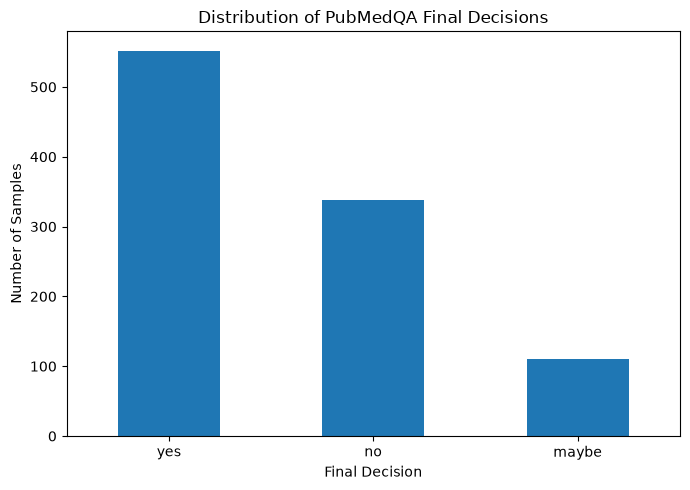

In [14]:
# Distribution of final decisions

decision_counts = df["final_decision"].value_counts()

print(decision_counts)

# Visualization
plt.figure(figsize=(7, 5))
decision_counts.plot(kind="bar")

plt.title("Distribution of PubMedQA Final Decisions")
plt.xlabel("Final Decision")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#### Important to see whether the data set is balance or not by checking yes no maybe

In [15]:
# Calculate question length in words

df["question_words"] = df["question"].apply(
    lambda x: len(x.split())
)

print(df["question_words"].describe())

count    1000.000000
mean       12.913000
std         4.100518
min         3.000000
25%        10.000000
50%        13.000000
75%        15.000000
max        31.000000
Name: question_words, dtype: float64


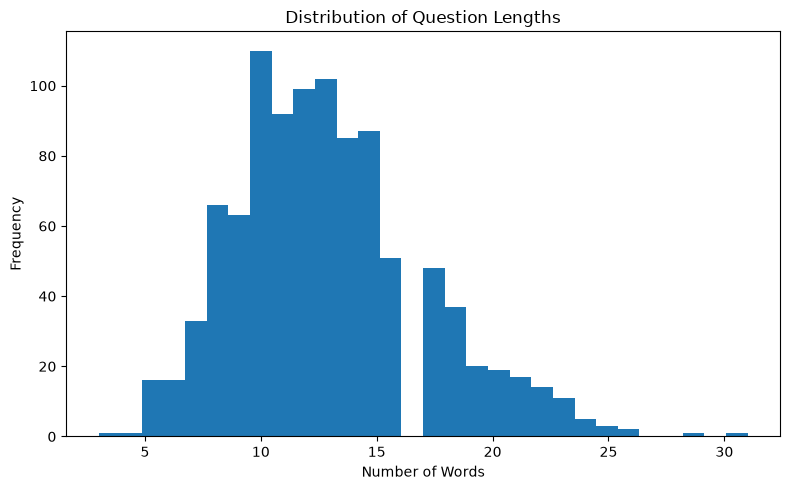

In [16]:
# Question Length:
plt.figure(figsize=(8, 5))

plt.hist(df["question_words"], bins=30)

plt.title("Distribution of Question Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [17]:
# Calculate context length in words

df["context_words"] = df["context"].apply(
    lambda x: len(x.split())
)

print(df["context_words"].describe())

count    1000.000000
mean      200.207000
std        51.846429
min        49.000000
25%       166.750000
50%       200.500000
75%       228.000000
max       398.000000
Name: context_words, dtype: float64


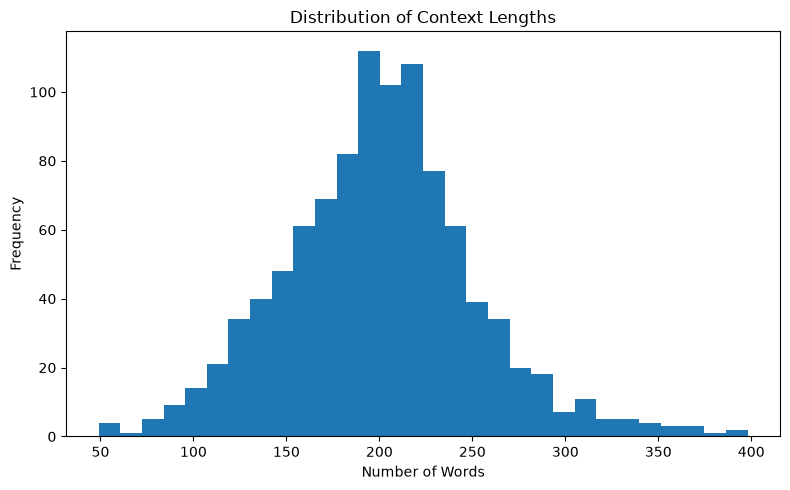

In [18]:
# Context Length Visulaization:
plt.figure(figsize=(8, 5))

plt.hist(df["context_words"], bins=30)

plt.title("Distribution of Context Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [19]:
# Calculate answer length in words

df["answer_words"] = df["long_answer"].apply(
    lambda x: len(x.split())
)

print(df["answer_words"].describe())

count    1000.000000
mean       39.660000
std        17.209432
min         8.000000
25%        27.000000
50%        37.000000
75%        49.000000
max       126.000000
Name: answer_words, dtype: float64


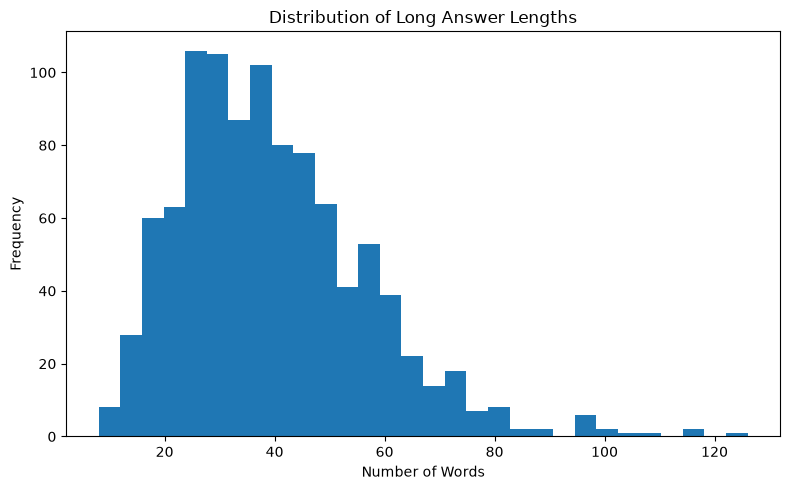

In [20]:
#Long Answer Length Visulaiation:
plt.figure(figsize=(8, 5))

plt.hist(df["answer_words"], bins=30)

plt.title("Distribution of Long Answer Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [21]:
# - Text	       Mean	        Median	  Max
# - Question   12.9 words	      13	  31
# - Context	 200.2 words	 200.5	  398
# - Answer	 39.7 words	      37	  126

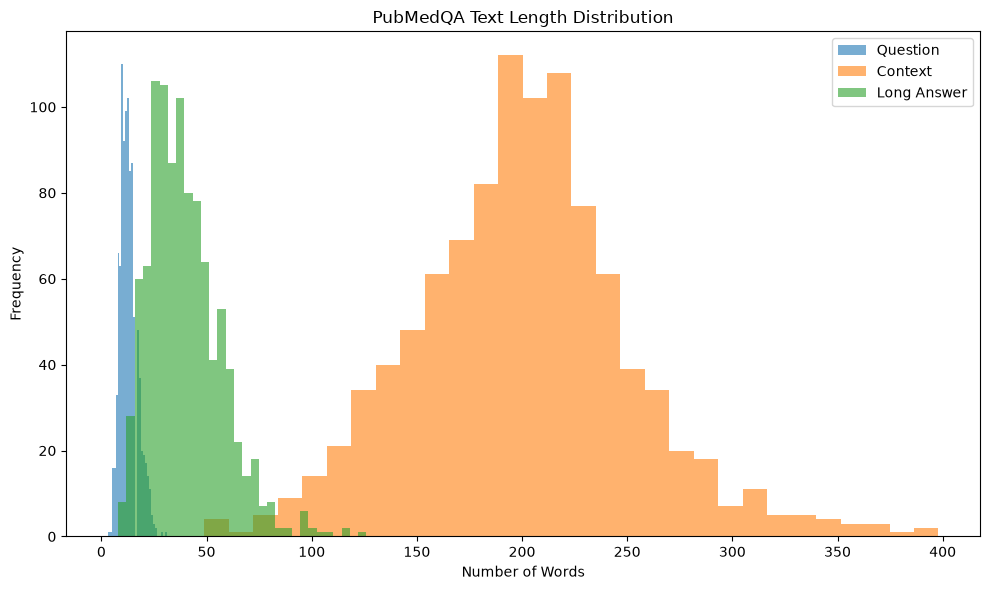

In [22]:
# Combined Length:
  
plt.figure(figsize=(10, 6))

plt.hist(
    df["question_words"],
    bins=30,
    alpha=0.6,
    label="Question"
)

plt.hist(
    df["context_words"],
    bins=30,
    alpha=0.6,
    label="Context"
)

plt.hist(
    df["answer_words"],
    bins=30,
    alpha=0.6,
    label="Long Answer"
)

plt.title("PubMedQA Text Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.legend()

plt.tight_layout()
plt.show()

In [23]:
# Checking Extrem Long Samples:
print("Longest questions:")
display(
    df.nlargest(5, "question_words")[
        ["question", "question_words"]
    ]
)

print("\nLongest contexts:")
display(
    df.nlargest(5, "context_words")[
        ["context_words", "context"]
    ]
)

print("\nLongest answers:")
display(
    df.nlargest(5, "answer_words")[
        ["answer_words", "long_answer"]
    ]
)

Longest questions:


,question,question_words
752,Contrast-enhanced MR imaging of hand and finge...,31
839,Prostate bed target interfractional motion usi...,29
472,Is semi-closed endarterectomy of the superfici...,26
968,Estradiol and Antagonist Pretreatment Prior to...,26
353,Improvements in survival of gynaecological can...,25



Longest contexts:


,context_words,context
319,398,To assess the results of transsphenoidal pitui...
956,395,The differential diagnosis between essential t...
496,380,The hypothesis of this prospective study is th...
467,374,Some of the disagreements on the perception of...
188,368,To determine whether successful completion of ...



Longest answers:


,answer_words,long_answer
499,126,The results of this study cast doubt on the im...
84,118,We have demonstrated that approaching a contra...
649,115,There was a statistically significant differen...
813,110,After comparing MR with arthroscopic findings ...
4,105,The effects of the intervention were most pron...


In [24]:
# Checking Missing values in year:
# Convert year to numeric
df["year_numeric"] = pd.to_numeric(
    df["year"],
    errors="coerce"
)

print("Missing years:", df["year_numeric"].isna().sum())

print("\nYear statistics:")
print(df["year_numeric"].describe())

Missing years: 58

Year statistics:
count     942.000000
mean     2008.887473
std         5.744847
min      1989.000000
25%      2005.000000
50%      2010.000000
75%      2014.000000
max      2017.000000
Name: year_numeric, dtype: float64


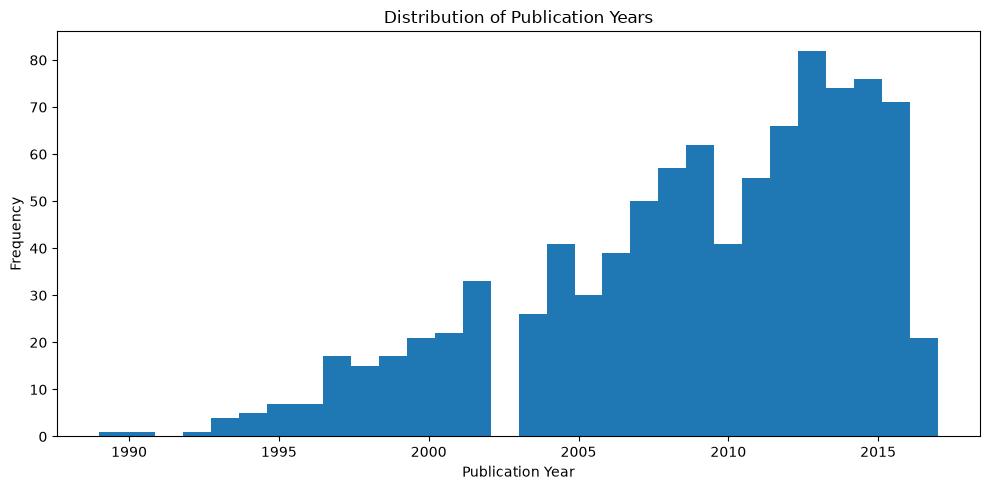

In [25]:
# Visualizing Missing:

plt.figure(figsize=(10, 5))

df["year_numeric"].dropna().plot(
    kind="hist",
    bins=30
)

plt.title("Distribution of Publication Years")
plt.xlabel("Publication Year")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [26]:
# Duplicates:
duplicate_questions = df["question"].duplicated().sum()

print("Duplicate questions:", duplicate_questions)

Duplicate questions: 0


In [27]:
# Unwanted Text Check for Text cleaning:
def check_whitespace(text):
    return text != text.strip() or "  " in text

print(
    "Questions with extra whitespace:",
    df["question"].apply(check_whitespace).sum()
)

print(
    "Contexts with extra whitespace:",
    df["context"].apply(check_whitespace).sum()
)

print(
    "Answers with extra whitespace:",
    df["long_answer"].apply(check_whitespace).sum()
)

Questions with extra whitespace: 2
Contexts with extra whitespace: 4
Answers with extra whitespace: 0


In [28]:
# Cleaning the text:
# Basic text cleaning
# We only remove unnecessary leading/trailing whitespace.
# We do NOT remove scientific symbols or biomedical terminology because they might be usefull.

df["question"] = df["question"].str.strip()
df["context"] = df["context"].str.strip()
df["long_answer"] = df["long_answer"].str.strip()

In [29]:
#veryfing:
# Basic text cleaning
# We only remove unnecessary leading/trailing whitespace.
# We do NOT remove scientific symbols or biomedical terminology.

import re

def clean_text(text):
    # Remove leading/trailing whitespace
    text = text.strip()

    # Replace multiple whitespace characters with a single space
    text = re.sub(r"\s+", " ", text)

    return text

df["question"] = df["question"].apply(clean_text)
df["context"] = df["context"].apply(clean_text)
df["long_answer"] = df["long_answer"].apply(clean_text)

In [30]:
print("Question whitespace issues:",
      df["question"].apply(check_whitespace).sum())

print("Context whitespace issues:",
      df["context"].apply(check_whitespace).sum())

print("Answer whitespace issues:",
      df["long_answer"].apply(check_whitespace).sum())

Question whitespace issues: 0
Context whitespace issues: 0
Answer whitespace issues: 0


In [32]:
#Source = the information we give to the model.
#Target = the answer we want the model to learn to generate.
#SOURCE
#────────────────────────────
#Question + Context
#────────────────────────────
#              ↓
#         Transformer
#              ↓
#TARGET
#────────────────────────────
#Long Answer
#────────────────────────────
# we simply want answer a long detailed answer so for that we need to feed the model question and the context of it so it can genrate the answer.

In [33]:
# Create source and target text for the Transformer

df["source"] = (
    "question: " + df["question"] +
    " context: " + df["context"]
)

df["target"] = df["long_answer"]

print("Source example:\n")
print(df["source"].iloc[0])

print("\n" + "=" * 80 + "\n")

print("Target example:\n")
print(df["target"].iloc[0])

Source example:

question: Do mitochondria play a role in remodelling lace plant leaves during programmed cell death? context: Programmed cell death (PCD) is the regulated death of cells within an organism. The lace plant (Aponogeton madagascariensis) produces perforations in its leaves through PCD. The leaves of the plant consist of a latticework of longitudinal and transverse veins enclosing areoles. PCD occurs in the cells at the center of these areoles and progresses outwards, stopping approximately five cells from the vasculature. The role of mitochondria during PCD has been recognized in animals; however, it has been less studied during PCD in plants. The following paper elucidates the role of mitochondrial dynamics during developmentally regulated PCD in vivo in A. madagascariensis. A single areole within a window stage leaf (PCD is occurring) was divided into three areas based on the progression of PCD; cells that will not undergo PCD (NPCD), cells in early stages of PCD (EPCD)

In [34]:
#checking that all 1,000 source-target pairs exist:
print("Number of source samples:", df["source"].notna().sum())
print("Number of target samples:", df["target"].notna().sum())

print("\nSource length (characters):", df["source"].str.len().describe())
print("\nTarget length (characters):", df["target"].str.len().describe())

Number of source samples: 1000
Number of target samples: 1000

Source length (characters): count    1000.000000
mean     1455.448000
std       349.912149
min       392.000000
25%      1243.750000
50%      1457.000000
75%      1658.000000
max      2824.000000
Name: source, dtype: float64

Target length (characters): count    1000.000000
mean      268.366000
std       117.674753
min        63.000000
25%       182.000000
50%       251.000000
75%       335.250000
max       827.000000
Name: target, dtype: float64


In [ ]:
#Train / Validation / Test Split:
#1000 to :---
#80% → Training     = 800  Transformer learns from this data
#10% → Validation   = 100  Used while developing the model
#10% → Testing      = 100  how well the model works on unseen examples

In [36]:
# Train , Validation , Test split:-
from sklearn.model_selection import train_test_split

# First: 80% training, 20% temporary
train_df, temp_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42
)

# Split the remaining 20% into:
# 10% validation + 10% test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42
)

In [37]:
#Shape of the data after spliting:-
print("Training set:", train_df.shape)
print("Validation set:", val_df.shape)
print("Test set:", test_df.shape)

Training set: (800, 12)
Validation set: (100, 12)
Test set: (100, 12)


In [38]:
# Get PMIDs from each split

train_ids = set(train_df["pmid"])
val_ids = set(val_df["pmid"])
test_ids = set(test_df["pmid"])

# Check overlap

print("Train ∩ Validation:", len(train_ids & val_ids))
print("Train ∩ Test:", len(train_ids & test_ids))
print("Validation ∩ Test:", len(val_ids & test_ids))

Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0


In [39]:
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

train_df.to_csv(PROCESSED_DIR / "train.csv", index=False)
val_df.to_csv(PROCESSED_DIR / "validation.csv", index=False)
test_df.to_csv(PROCESSED_DIR / "test.csv", index=False)

print("Processed datasets saved successfully!")

Processed datasets saved successfully!
